<a href="https://colab.research.google.com/github/VishnuCodes96/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP5_StuntingRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import seaborn as sns

## Loading & Understanding the data

In [2]:
from google.colab import files
uploaded = files.upload()

Saving mp5_nfhs5_district_health.csv to mp5_nfhs5_district_health.csv


In [3]:
df = pd.read_csv('mp5_nfhs5_district_health.csv')
df.head()

,state,district,stunted_children_pct,wasted_children_pct,underweight_children_pct,women_10yrs_school_pct,women_literate_pct,child_marriage_pct,improved_sanitation_pct,improved_water_pct,...,institutional_births_pct,full_vaccination_pct,anc_4visits_pct,health_insurance_pct,adequate_diet_pct,anaemic_children_pct,anaemic_women_pct,women_low_bmi_pct,teen_pregnancy_pct,is_aspirational
0,Andaman & Nicobar Islands,Nicobar,21.6,15.7,24.6,53.5,87.5,11.4,83.5,98.8,...,97.8,64.2,71.7,2.7,18.7,37.7,38.3,8.2,1.8,0
1,Andaman & Nicobar Islands,North & Middle Andaman,27.0,27.0,42.8,41.0,84.0,15.4,86.4,92.2,...,97.7,0.0,79.2,2.1,5.9,30.4,62.1,8.6,3.8,0
2,Andaman & Nicobar Islands,South Andaman,21.1,12.6,17.4,57.5,86.7,17.1,89.3,97.9,...,99.5,76.3,85.9,1.2,23.5,43.4,57.7,10.0,2.8,0
3,Andhra Pradesh,Anantapur,36.0,19.3,40.6,31.3,63.6,37.3,71.3,98.8,...,94.7,81.8,66.6,73.2,2.9,55.8,50.5,21.9,13.6,0
4,Andhra Pradesh,Chittoor,27.1,14.8,27.9,40.3,69.3,28.1,74.6,98.5,...,97.1,66.6,65.3,70.7,6.0,54.9,51.8,20.1,19.7,0


In [4]:
print(f'No. of Rows & Columns: {df.shape}')
print("==" * 30)
print("DATA OVERVIEW")
print("==" * 30)
print(df.info())

No. of Rows & Columns: (707, 22)
DATA OVERVIEW
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 707 entries, 0 to 706
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   state                     707 non-null    object 
 1   district                  707 non-null    object 
 2   stunted_children_pct      707 non-null    float64
 3   wasted_children_pct       707 non-null    float64
 4   underweight_children_pct  707 non-null    float64
 5   women_10yrs_school_pct    707 non-null    float64
 6   women_literate_pct        707 non-null    float64
 7   child_marriage_pct        707 non-null    float64
 8   improved_sanitation_pct   707 non-null    float64
 9   improved_water_pct        707 non-null    float64
 10  clean_cooking_fuel_pct    707 non-null    float64
 11  electricity_pct           707 non-null    float64
 12  institutional_births_pct  707 non-null    float64
 13  full_vaccination_p

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
stunted_children_pct,707.0,33.463791,8.558704,0.0,27.30,32.8,39.20,60.6
wasted_children_pct,707.0,18.511881,6.515121,0.0,13.90,18.1,22.75,48.0
underweight_children_pct,707.0,29.460113,9.738311,0.0,22.05,29.3,36.20,62.4
women_10yrs_school_pct,707.0,40.267185,14.308171,0.0,28.95,39.2,49.90,88.2
women_literate_pct,707.0,72.984017,13.007541,0.0,64.40,73.8,82.90,99.7
child_marriage_pct,707.0,20.637058,12.802683,0.0,10.85,18.3,28.20,80.9
improved_sanitation_pct,707.0,71.843989,14.541987,0.0,62.00,73.7,83.30,99.9
improved_water_pct,707.0,93.646959,9.348504,0.0,92.05,97.0,99.30,100.0
clean_cooking_fuel_pct,707.0,54.092221,24.275144,0.0,33.95,50.4,75.35,99.8
electricity_pct,707.0,96.868883,5.676925,0.0,96.40,98.7,99.50,100.0


### Key observations:
1. 0% filled the `min` column which looks impossible.
2. `teen_pregnancy_pct` has a max value of 91.9% which seems unusually high compared to 75th percentile which has value of 8.65%

### Counting how many zeros each column has

In [6]:
# Count the number of zeros in each column
zero_counts = (df == 0).sum()

# Display the results
print(zero_counts.sort_values(ascending=False))

is_aspirational             595
teen_pregnancy_pct           18
full_vaccination_pct         14
adequate_diet_pct             7
child_marriage_pct            2
wasted_children_pct           1
institutional_births_pct      1
electricity_pct               1
women_10yrs_school_pct        1
underweight_children_pct      1
stunted_children_pct          1
improved_water_pct            1
improved_sanitation_pct       1
women_literate_pct            1
anaemic_children_pct          1
health_insurance_pct          1
clean_cooking_fuel_pct        1
anc_4visits_pct               1
women_low_bmi_pct             1
anaemic_women_pct             1
state                         0
district                      0
dtype: int64


### Finding the row named "Data Not Available".

In [7]:
df[df['district'] == 'Data Not Available']

,state,district,stunted_children_pct,wasted_children_pct,underweight_children_pct,women_10yrs_school_pct,women_literate_pct,child_marriage_pct,improved_sanitation_pct,improved_water_pct,...,institutional_births_pct,full_vaccination_pct,anc_4visits_pct,health_insurance_pct,adequate_diet_pct,anaemic_children_pct,anaemic_women_pct,women_low_bmi_pct,teen_pregnancy_pct,is_aspirational
211,Jammu & Kashmir,Data Not Available,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


### Key Observation:
I will clean the row named "Data Not Available" from the dataset because it contains zero values across all numerical indicators, which likely represent missing data rather than actual district-level measurements. Keeping this row could distort the statistical analysis and negatively affect the accuracy of our linear regression model.

## Cleaning the Data

In [8]:
df = df[df['district'] != 'Data Not Available'] # Removing the "Data Not Available" row
df.shape # 707 rows - 1 = 706 rows

(706, 22)

In [9]:
# Identify percentage columns
percentage_cols = df.columns[df.columns.str.endswith('_pct')]

# Replace 0 with NaN in percentage columns
df[percentage_cols] = df[percentage_cols].replace(0, np.nan)

In [10]:
df['teen_pregnancy_pct'].sort_values(ascending=False).head(5)

,teen_pregnancy_pct
107,91.9
297,80.3
694,27.3
591,26.9
595,26.6


### Key Observations:
The highest two values (91.9% and 80.3%) appear unusually high compared with the remaining observations and may indicate data quality issues. Therefore, I will exclude this column from the model features.

In [11]:
# Print dataset shape
print("Dataset shape:", df.shape)

# Print missing-value count for each column
print("\nMissing values per column:")
print(df.isnull().sum())

Dataset shape: (706, 22)

Missing values per column:
state                        0
district                     0
stunted_children_pct         0
wasted_children_pct          0
underweight_children_pct     0
women_10yrs_school_pct       0
women_literate_pct           0
child_marriage_pct           1
improved_sanitation_pct      0
improved_water_pct           0
clean_cooking_fuel_pct       0
electricity_pct              0
institutional_births_pct     0
full_vaccination_pct        13
anc_4visits_pct              0
health_insurance_pct         0
adequate_diet_pct            6
anaemic_children_pct         0
anaemic_women_pct            0
women_low_bmi_pct            0
teen_pregnancy_pct          17
is_aspirational              0
dtype: int64


### Visualising Stunted Children Percentage

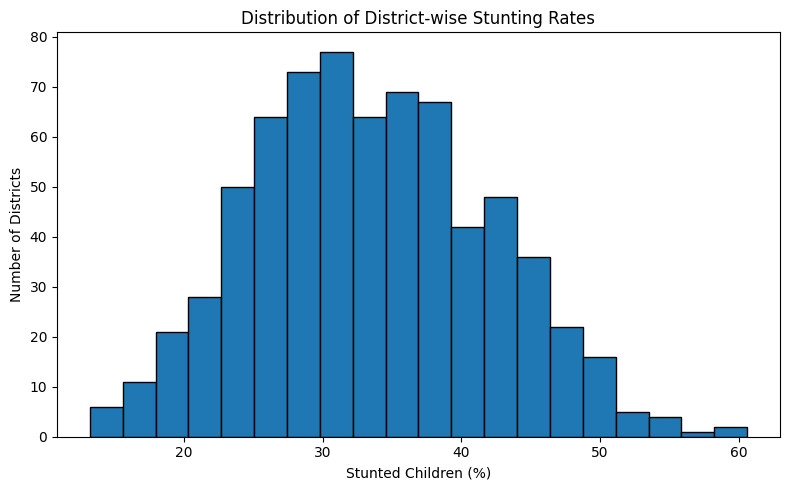

In [12]:
plt.figure(figsize=(8, 5))

plt.hist(df['stunted_children_pct'], bins=20, edgecolor='black')

plt.xlabel('Stunted Children (%)')
plt.ylabel('Number of Districts')
plt.title('Distribution of District-wise Stunting Rates')
plt.tight_layout()
plt.show()

### Key Observations:
1. What is the typical district?

* Most districts have a stunting rate between 25% and 40%, with the highest concentration around 30–32%. Therefore, a typical district has approximately 30–35% of children classified as stunted.

2. Is the shape skewed?

* The distribution is slightly positively (right) skewed. Most districts are concentrated around 25–40%, while a smaller number of districts extend towards higher stunting rates (50–60%), creating a longer tail on the right.

### Calculating correlation of every column with stunting

In [13]:
correlation = df.select_dtypes(include='number').corr()['stunted_children_pct'].sort_values(ascending=False)
print(correlation)

stunted_children_pct        1.000000
underweight_children_pct    0.701788
women_low_bmi_pct           0.552092
child_marriage_pct          0.426367
anaemic_children_pct        0.331509
is_aspirational             0.298902
wasted_children_pct         0.238255
anaemic_women_pct           0.238045
teen_pregnancy_pct          0.146764
improved_water_pct         -0.037207
health_insurance_pct       -0.121148
full_vaccination_pct       -0.195079
adequate_diet_pct          -0.234880
anc_4visits_pct            -0.360826
institutional_births_pct   -0.380700
clean_cooking_fuel_pct     -0.412485
electricity_pct            -0.427657
improved_sanitation_pct    -0.502898
women_literate_pct         -0.538993
women_10yrs_school_pct     -0.540876
Name: stunted_children_pct, dtype: float64


### Strongest positive correlation
| Variable | Correlation | Interpretation |
| --- | --- | --- |
| underweight_children_pct | +0.702	| Strong positive relationship |
| women_low_bmi_pct |	+0.552	| Moderate positive relationship |
| child_marriage_pct |	+0.426 |	Moderate positive relationship |
| anaemic_children_pct |	+0.332 |	Weak-to-moderate positive relationship |

Districts with higher proportions of underweight children and women with low BMI tend to have higher stunting rates.

### Strongest negative correlations
| Variable | Correlation | Interpretation |
| --- | --- | --- |
| women_10yrs_school_pct | -0.541	| Moderate negative relationship |
| women_literate_pct | -0.539 | Moderate negative relationship |
| improved_sanitation_pct | -0.503 |  Moderate negative relationship |

Districts with higher female literacy, education and improved sanitation tend to have lower child stunting rates.

### Interesting Patterns:
1. **Nutritional indicators**: Underweight children have the strongest positive correlation with stunting (+0.702). This suggests that the two nutritional outcomes frequently occur together.
2. **Women's education**: Female education has a negative correlation with stunting (-0.541), suggesting that districts with better female education tend to have lower stunting rates.
3. **Living conditions**: Improved sanitation (-0.503) and electricity (-0.428) also show negative associations with stunting.

* These are correlations, not evidence of causation. We cannot conclude that improving one indicator will automatically reduce stunting.

### Visualizing correlations between stunting and available 8 features

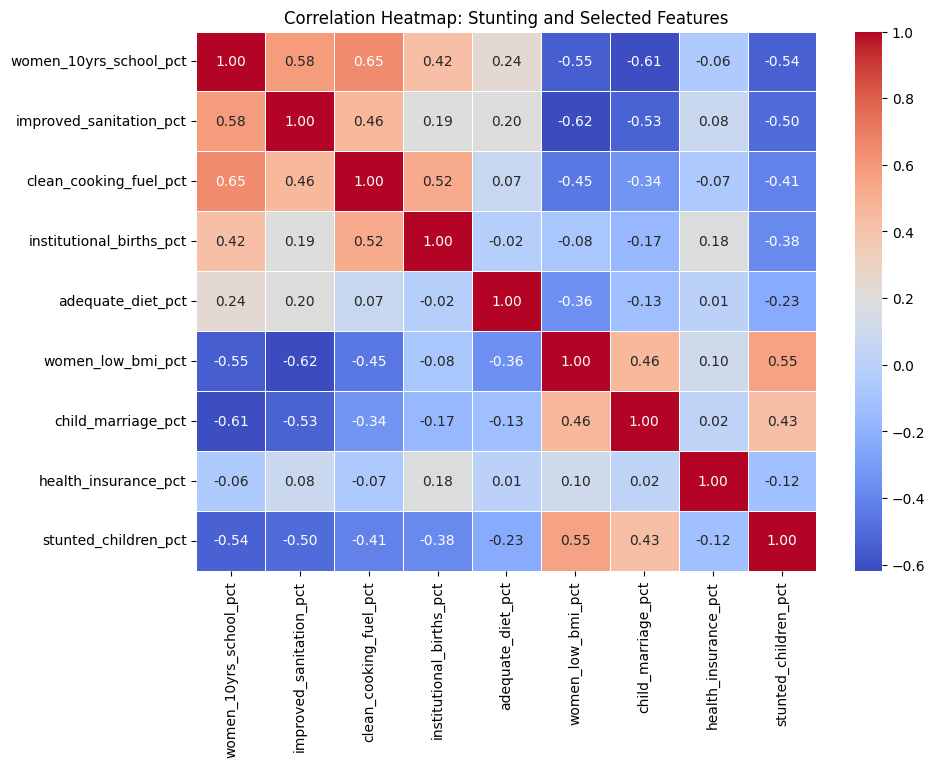

In [14]:
# Define the 8 features
features = [
    "women_10yrs_school_pct",
    "improved_sanitation_pct",
    "clean_cooking_fuel_pct",
    "institutional_births_pct",
    "adequate_diet_pct",
    "women_low_bmi_pct",
    "child_marriage_pct",
    "health_insurance_pct"
]

# Calculate correlations with stunting
corr = df[features + ['stunted_children_pct']].corr()

# Plot the heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap: Stunting and Selected Features')
plt.show()

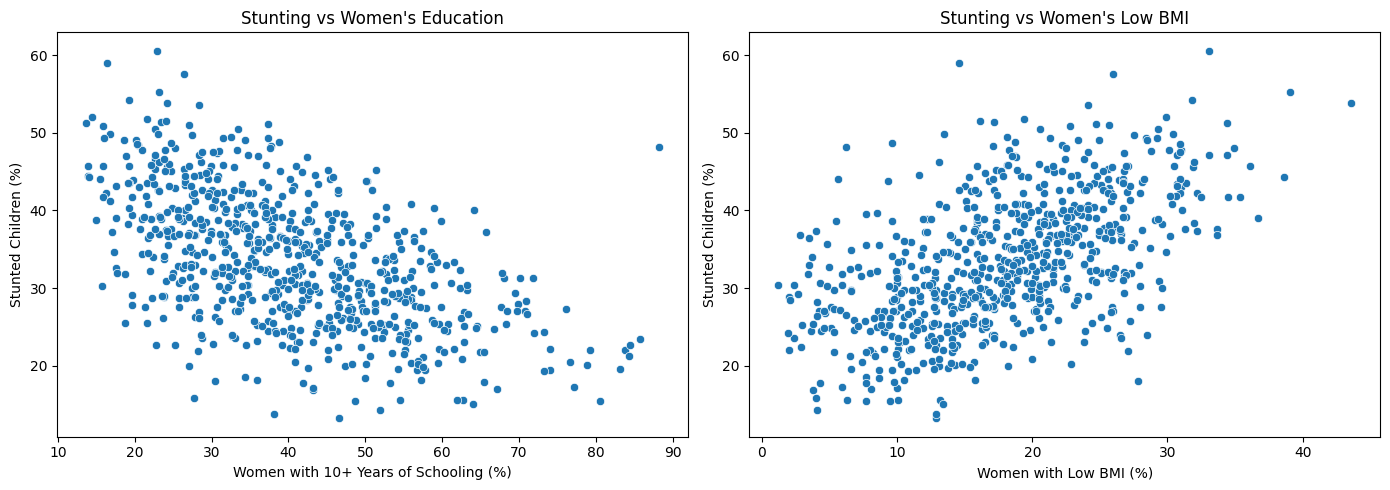

In [15]:
# Create two scatter plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Stunting vs Women's Education
sns.scatterplot(
    data=df,
    x='women_10yrs_school_pct',
    y='stunted_children_pct',
    ax=axes[0]
)

axes[0].set_title("Stunting vs Women's Education")
axes[0].set_xlabel('Women with 10+ Years of Schooling (%)')
axes[0].set_ylabel('Stunted Children (%)')

# Plot 2: Stunting vs Women's Low BMI
sns.scatterplot(
    data=df,
    x='women_low_bmi_pct',
    y='stunted_children_pct',
    ax=axes[1]
)

axes[1].set_title("Stunting vs Women's Low BMI")
axes[1].set_xlabel('Women with Low BMI (%)')
axes[1].set_ylabel('Stunted Children (%)')

plt.tight_layout()
plt.show()

### Scatter Plot Observations

1. **Women's Education:** A negative relationship is observed between women's education and child stunting. Districts with higher percentages of women completing 10 or more years of schooling generally have lower stunting rates.

2. **Women's Low BMI:** A positive relationship is observed between women's low BMI and child stunting. Districts with higher percentages of women having low BMI generally experience higher stunting rates.

**Conclusion:** Both features show visible linear relationships with child stunting, making them useful candidates for the regression model. However, these relationships do not establish causation.

## Simple regression: one factor (women_10yrs_school_pct)

### Dropping the rows where the feature or the target is missing

In [16]:
df_simple = df.dropna(
    subset=['women_10yrs_school_pct', 'stunted_children_pct']
)

### Splitting into train and test sets

In [17]:
from sklearn.model_selection import train_test_split

X = df_simple[['women_10yrs_school_pct']]
y = df_simple['stunted_children_pct']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

### Training a LinearRegression model

In [18]:
from sklearn.linear_model import LinearRegression

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Print coefficient and intercept
print("Coefficient:", round(model.coef_[0],3))
print("Intercept:", round(model.intercept_,3))

Coefficient: -0.331
Intercept: 46.91


### The Equation looks like:
`Stunting = 46.91 - 0.331 * Women's Education`


* -0.331 Coefficient means that for every 1 percentage-point increase in women completing 10 or more years of schooling, the model predicts a 0.331 percentage-point decrease in the district's stunting rate, on average.

* 46.91 Intercept means means that when women's education is 0%, the model predicts a stunting rate of 46.91%.

* Higher female educational attainment is associated with lower child stunting rates across districts. The model estimates that a 10 percentage-point improvement in women's education corresponds to a 3.31 percentage-point reduction in predicted stunting.

* This is an association identified by the model, not proof that increasing women's education directly causes stunting to decrease.

In [19]:
from sklearn.metrics import r2_score, mean_squared_error

# Predict on test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Print results
print("R2 Score:", round(r2,3))
print("RMSE:", round(rmse,3))

R2 Score: 0.22
RMSE: 7.3


### Key Observations:
1. Interpret r2 = 0.22
* The model explains approximately 22% of the variation in district-level stunting rates using women's education alone.
* The remaining 78% of variation is not explained by this model.
* This suggests that women's education is an important factor associated with stunting, but it cannot explain the differences in stunting rates across districts on its own.
2. Interpret RMSE = 7.3
* The model's prediction errors have a root mean squared magnitude of approximately 7.3 percentage points.
* For example, if the actual stunting rate is 35%, the model might predict 27.7% or 42.3%.

These are illustrative differences, not actual predictions from your test set.

For every 10 percentage-point increase in women with 10+ years of schooling, the predicted district stunting rate is about **3.31 percentage points lower**, on average.

### Visualizing the trend

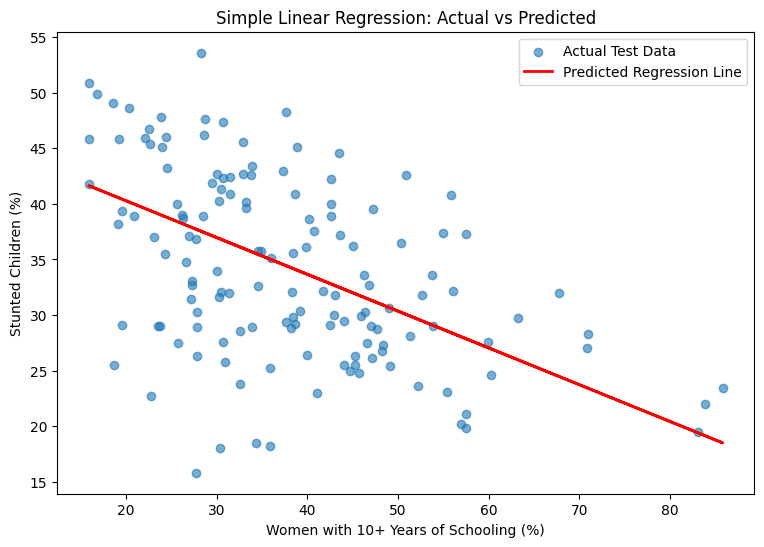

In [20]:
# Plot actual test points
plt.figure(figsize=(9, 6))

plt.scatter(
    X_test['women_10yrs_school_pct'],
    y_test,
    label='Actual Test Data',
    alpha=0.6
)

# Plot fitted regression line
plt.plot(
    X_test['women_10yrs_school_pct'],
    y_pred,
    color='red',
    linewidth=2,
    label='Predicted Regression Line'
)

plt.xlabel('Women with 10+ Years of Schooling (%)')
plt.ylabel('Stunted Children (%)')
plt.title('Simple Linear Regression: Actual vs Predicted')
plt.legend()
plt.show()

### Key Observations:
Women's education is associated with lower child stunting rates, but districts with similar education levels can still have considerably different stunting rates. This suggests that other socioeconomic, nutritional and healthcare factors also contribute to district-level differences.

## Multiple regression with eight factors

In [21]:
# Drop rows with missing values in any feature or target
df_multiple = df.dropna(subset=features + ['stunted_children_pct'])

# Count remaining districts
print("Remaining districts:", df_multiple.shape[0])

Remaining districts: 699


In [22]:
X = df_multiple[features] # 8 Features
y = df_multiple['stunted_children_pct']

# Split into training and testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Train the multiple linear regression model
model_multiple = LinearRegression()
model_multiple.fit(X_train, y_train)

print("Coefficients:", round(model_multiple.coef_[0],3), round(model_multiple.coef_[1],3), round(model_multiple.coef_[2],3), round(model_multiple.coef_[3],3),
      round(model_multiple.coef_[4],3), round(model_multiple.coef_[5],3), round(model_multiple.coef_[6],3), round(model_multiple.coef_[7],3)
      )
print("Intercept:", round(model_multiple.intercept_,3))

Coefficients: -0.093 -0.038 0.012 -0.176 -0.027 0.469 0.052 -0.038
Intercept: 47.205


### Key Observations:
* Each coefficient represents the expected change in stunting for a one percentage-point increase in that particular feature, while keeping all other features constant.

* After accounting for eight socioeconomic and health indicators simultaneously, women's low BMI has a positive coefficient of 0.469, indicating that districts with poorer women's nutritional status tend to have higher child stunting. Women's education and institutional births have negative coefficients, suggesting associations with lower stunting. This indicates that child stunting is associated with multiple interconnected factors rather than a single indicator.

In [23]:
y_pred_multiple = model_multiple.predict(X_test)

# Calculate evaluation metrics
r2_multiple = r2_score(y_test, y_pred_multiple)
rmse_multiple = np.sqrt(mean_squared_error(y_test, y_pred_multiple))

print("R2 Score:", round(r2_multiple,3))
print("RMSE:", round(rmse_multiple,3))

R2 Score: 0.45
RMSE: 5.858


### Model Performance Comparison

The multiple linear regression model performed better than the simple regression model. R2 improved from 0.22 to 0.45, indicating that the eight features explain a greater proportion of variation in district-level stunting rates. RMSE decreased from 7.3 to 5.858 percentage points, indicating lower prediction errors.

**Conclusion:** Including multiple socioeconomic, nutritional and healthcare indicators improved the model's predictive performance compared with using women's education alone.

### Making a table of the eight coefficients

In [24]:
# Create a coefficient table
coef_table = pd.DataFrame({
    'Feature': features,
    'Coefficient': model_multiple.coef_
})

# Sort from most negative to most positive
coef_table = coef_table.sort_values(
    by='Coefficient', ascending=True
).reset_index(drop=True)

print(coef_table)

                    Feature  Coefficient
0  institutional_births_pct    -0.176089
1    women_10yrs_school_pct    -0.092602
2      health_insurance_pct    -0.037813
3   improved_sanitation_pct    -0.037551
4         adequate_diet_pct    -0.026755
5    clean_cooking_fuel_pct     0.012452
6        child_marriage_pct     0.051774
7         women_low_bmi_pct     0.468692


### Coefficient Analysis

Institutional births have the strongest negative coefficient (-0.176), while women's low BMI has the strongest positive coefficient (+0.469). Women's education also has a negative coefficient (-0.093), suggesting an inverse association with stunting after accounting for the other seven factors. Overall, the results highlight the interconnected relationship between maternal health, healthcare access and child nutrition.

**Note:** These coefficients represent conditional associations, not causal effects.

| Feature |	Correlation |	Coefficient |	Signs match? |
| --- | --- | --- | --- |
| Women's education |	-0.541 | -0.093 |	Yes |
| Improved sanitation |	-0.503 |	-0.038 |	Yes |
| Clean cooking fuel |	-0.412 |	+0.012 |	**No** |
| Institutional births |	-0.381 |	-0.176 |	Yes |
| Adequate diet |	-0.235 |	-0.027 |	Yes |
| Women's low BMI |	+0.552 |	+0.469 |	Yes |
| Child marriage |	+0.426 |	+0.052 | Yes |
| Health insurance | -0.121 |	-0.038 |	Yes |

### Comparing Correlation and Regression Coefficients

Most of the eight features have regression coefficients with the same signs as their correlations with stunting. However, `clean_cooking_fuel_pct` has a negative correlation (-0.412) but a positive regression coefficient (+0.012), indicating a reversal in direction.

This can happen because several features overlap and are correlated with one another. In simple correlation, we examine the relationship between two variables independently, whereas multiple regression estimates the relationship of each feature with stunting while holding the other features constant. This overlap can change the direction and magnitude of individual coefficients, a phenomenon associated with multicollinearity.

## Where is the model most wrong ?

### Visualizing Actual vs Predicted values via scatter plot for multiple factor regression model

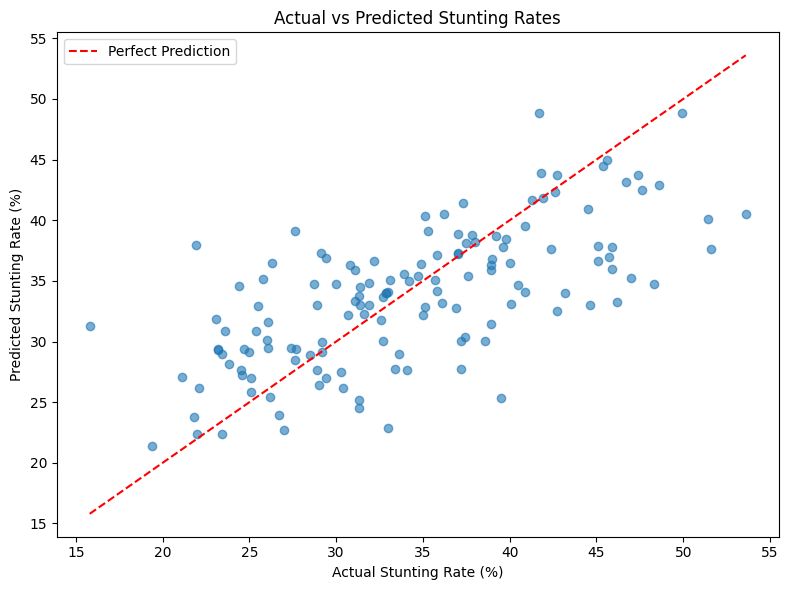

In [25]:
plt.figure(figsize=(8, 6))

# Scatter plot of actual vs predicted values
plt.scatter(y_test, y_pred_multiple, alpha=0.6)

# Diagonal reference line (Actual = Predicted)
min_val = min(y_test.min(), y_pred_multiple.min())
max_val = max(y_test.max(), y_pred_multiple.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Stunting Rate (%)')
plt.ylabel('Predicted Stunting Rate (%)')
plt.title('Actual vs Predicted Stunting Rates')
plt.legend()
plt.tight_layout()
plt.show()

### Key Observations:
1. **Overall pattern:** Most points follow an upward trend around the diagonal line, indicating that the model captures the broad variation in district stunting rates.
2. **Overprediction:** Points above the red line represent districts where the model predicted a higher stunting rate than the actual rate.
3. **Underprediction:** Points below the red line represent districts where the model predicted a lower stunting rate than the actual rate.
4. **Prediction errors:** Several points are considerably distant from the diagonal, indicating that the model struggles with certain districts.
5. **Regression towards the average:** The model tends to overpredict some districts with low actual stunting and underpredict some districts with high actual stunting.

**Interpretation**: Although the eight factors explain a reasonable proportion of variation in stunting, the model struggles to accurately capture district-specific differences, particularly at the extremes.

In [26]:
# Creating a copy of the complete dataset
df_predictions = df_multiple.copy()

# Predicting stunting for every district
df_predictions['predicted_stunting'] = model_multiple.predict(
    df_predictions[features]
)

# Calculating the gap between actual and predicted stunting
df_predictions['gap'] = (
    df_predictions['stunted_children_pct'] -
    df_predictions['predicted_stunting']
)

# Displaying the results
df_predictions[['state', 'district',
                'stunted_children_pct',
                'predicted_stunting',
                'gap']].head()

,state,district,stunted_children_pct,predicted_stunting,gap
0,Andaman & Nicobar Islands,Nicobar,21.6,26.433770,-4.833770
1,Andaman & Nicobar Islands,North & Middle Andaman,27.0,28.314517,-1.314517
2,Andaman & Nicobar Islands,South Andaman,21.1,27.049101,-5.949101
3,Andhra Pradesh,Anantapur,36.0,35.379809,0.620191
4,Andhra Pradesh,Chittoor,27.1,32.693976,-5.593976


### Note:
* Negative gap = model overestimates stunting.
* Positive gap = model underestimates stunting.
* Larger absolute gap = larger prediction error.

In [27]:
# Sort by gap in descending order and display the top 5
df_predictions.sort_values(by='gap', ascending=False)[
    ['state', 'district',
   'stunted_children_pct',
   'predicted_stunting',
   'gap']
    ].head(5)

,state,district,stunted_children_pct,predicted_stunting,gap
466,Puducherry,Mahe,48.2,19.941714,28.258286
404,Meghalaya,West Khasi Hills,59.0,40.557255,18.442745
280,Karnataka,Yadgir,57.6,40.449716,17.150284
8,Andhra Pradesh,Kurnool,50.5,35.278086,15.221914
322,Madhya Pradesh,Katni,49.5,34.859218,14.640782
